# DASCM 2026 — Project Part 2
## Dataset 1 — Manufacturing Energy Consumption (Regression)

**Course:** Data Analytics in Supply Chain Management — Fall 2026  
**Project:** Part 2 — Data Preprocessing  
**Dataset file:** `regression_manufacturing.csv`  
**Target:** `Energy_Consumption_kWh`  
**Preprocessing notebook:** Continuation of the corresponding Part 1 EDA.

### Group contribution declaration — complete before submission

| Group member | Contribution to this notebook |
|---|---|
| *Subhankar Biswas* | *Actual Contribution: 1. Preprocessing workflow and leakage control; 2. Imports and reproducibility; 3. Load source data and apply dataset-specific, traceable corrections; 4. Initial quality and target audit; 5. Identify and visualize missing values; 6. Define predictive inputs and split the data; 7. Handle missing predictor values; 8. Detect and handle outliers; 9. Encode categorical variables; 10. Scale numerical features; 11. Relationship diagnostics and preprocessing impact; 12. Other preprocessing decisions; 13. Export model-ready matrices and final checklist; 14. Findings and conclusion; 15. Data Visualization & Plots. Percentage Work-share = 100 %* |

### Scope and target

This notebook implements the Part 2 preprocessing requirements for this dataset. It does not train a final predictive model. It produces leakage-aware, train/test-ready feature matrices for the next modelling stage.

## 1. Preprocessing workflow and leakage control

The workflow follows this order:

1. Load the untouched source CSV and make a documented analysis copy.
2. Check dimensions, duplicate/identifier integrity, target completeness, data types and missingness.
3. Apply deterministic domain corrections and derive date/time features where justified.
4. Remove rows without a usable supervised target (only where necessary), then split into **80% training / 20% test**.
5. Fit missing-value imputers, IQR outlier bounds, categorical encoders and feature scalers on the **training partition only**; apply the fitted transformations to the test partition.
6. Compare distributions before and after missing-data, outlier and scaling treatments, then export the processed matrices.

**Why 80/20?** An 80% training sample generally provides enough examples to estimate preprocessing statistics and later fit a model, while the 20% hold-out set remains large enough for a meaningful first evaluation. For the classification dataset, stratification preserves class proportions in both partitions.

**Why split before imputation, winsorization, encoding and scaling?** Their fitted statistics or category vocabularies must be learned from training data only. Fitting these steps on the complete dataset would allow information from the test set to influence the training process (data leakage). Deterministic field corrections and time-feature extraction do not estimate distributional parameters, so they are performed before splitting.

The source CSV is never overwritten. `raw` is the in-memory source snapshot and `df` is the separate analysis copy.

## 2. Imports and reproducibility

In [39]:
# Reproducible environment and libraries
from pathlib import Path
import warnings, inspect, json
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display, Markdown
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, RobustScaler
from sklearn.metrics import classification_report

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 80)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

try:
    import missingno as msno
    HAS_MISSINGNO = True
except ImportError:
    HAS_MISSINGNO = False
    print("missingno is not installed in this environment. The notebook will show an equivalent missingness heatmap fallback.")
    print("To render the requested missingno plots, install requirements.txt (includes missingno).")

In [40]:
from pathlib import Path
import matplotlib.pyplot as plt

# Create output directory
PLOTS_DIR = Path("part2_plots") / "Notebook-1"
PLOTS_DIR.mkdir(parents=True, exist_ok=True)

def save_plot(filename, dpi=300):
    """Save the current Matplotlib figure as a high-resolution PNG."""
    filepath = PLOTS_DIR / filename

    plt.tight_layout()
    plt.savefig(
        filepath,
        dpi=dpi,
        bbox_inches="tight",
        facecolor="white"
    )

    print(f"Plot saved: {filepath.resolve()}")

In [41]:
# File and target configuration
DATA_PATH = Path("regression_manufacturing.csv")
if not DATA_PATH.exists():
    DATA_PATH = Path("../data/regression_manufacturing.csv")
assert DATA_PATH.exists(), f"Dataset not found: {DATA_PATH}. Place regression_manufacturing.csv beside this notebook."
TARGET = 'Energy_Consumption_kWh'
TASK = 'regression'
EXCLUDE_FEATURES = ['Observation_ID']
OUTLIER_SKIP = ['Product_Complexity_Index', 'Spindle_Load_pct', 'Humidity_pct']
print("Dataset path:", DATA_PATH.resolve())
print("Target:", TARGET, "| Task:", TASK)

Dataset path: /Users/subhankarbiswas/MSCM-CO-07_Data-Analytics-in-Supply-Chain-Management_Team_Project/data/regression_manufacturing.csv
Target: Energy_Consumption_kWh | Task: regression


## 3. Load source data and apply dataset-specific, traceable corrections

The operations in the next cell are specific to this dataset. They do not alter the CSV on disk. For datasets with 10,250 rows, the Part 1 review established that IDs 1–10,000 form the ordered canonical block; later appended records repeat IDs and include unresolved conflicting copies. The analysis therefore uses the first 10,000 rows provisionally, with the source-level discrepancy documented rather than resolved by arbitrary row deletion.

In [42]:
# Canonical dataset scope: first 10,000 IDs (1..10,000), as documented in Part 1.
# The CSV itself is never overwritten or modified.
raw = pd.read_csv(DATA_PATH)
if len(raw) >= 10000 and raw["Observation_ID"].head(10000).tolist() == list(range(1, 10001)):
    df = raw.iloc[:10000].copy()
    scope_note = "Selected rows 1–10,000: the canonical unique-ID block; appended rows are excluded from this modelling table."
else:
    df = raw.copy()
    scope_note = "The expected 1..10,000 canonical ID block was not detected; the full file is retained and the scope must be confirmed."

# Stable machine-level mapping for five invalid 'Tree' labels.
non_tree = df.loc[df["Machine_Type"].ne("Tree") & df["Machine_Type"].notna()]
machine_type_map = non_tree.groupby("Machine_ID")["Machine_Type"].agg(lambda s: s.mode().iloc[0] if not s.mode().empty else np.nan)
tree_mask = df["Machine_Type"].eq("Tree")
df.loc[tree_mask, "Machine_Type"] = df.loc[tree_mask, "Machine_ID"].map(machine_type_map)
if df.loc[tree_mask, "Machine_Type"].isna().any():
    raise ValueError("At least one Tree machine label could not be resolved from Machine_ID; ask the data owner.")
# 'Dream' is not one of the assignment's allowed shifts; retain as missing rather than guessing.
df["Shift"] = df["Shift"].replace({"Dream": np.nan})

prod_date = pd.to_datetime(df["Production_Date"], errors="coerce")
df["production_month"] = prod_date.dt.month
df["production_dayofweek"] = prod_date.dt.dayofweek
df["production_dayofyear"] = prod_date.dt.dayofyear
df["production_is_weekend"] = (prod_date.dt.dayofweek >= 5).astype("boolean")
df = df.drop(columns=["Production_Date"])
print(scope_note)
print("Canonical shape:", df.shape)
print("Tree labels corrected:", int(tree_mask.sum()))
print("Remaining invalid Machine_Type labels:", sorted(set(df["Machine_Type"].dropna()) - {"CNC_Mill", "CNC_Lathe", "CNC_Grinder", "Laser_Cutter"}))
print("Unresolved Shift labels converted to missing:", int(df["Shift"].isna().sum()) - int(raw["Shift"].isna().sum()))

Selected rows 1–10,000: the canonical unique-ID block; appended rows are excluded from this modelling table.
Canonical shape: (10000, 23)
Tree labels corrected: 5
Remaining invalid Machine_Type labels: []
Unresolved Shift labels converted to missing: 5


## 4. Initial quality and target audit

The audit records dimensions, duplicate rows, identifier uniqueness, types, summary statistics, category cardinalities and target distribution. A numeric identifier is not assumed to be a continuous predictor.

Analysis shape: (10000, 23)
Exact duplicate rows: 0
Observation_ID unique: 10000 of 10000

Data types:


,dtype
Observation_ID,int64
Machine_ID,object
Machine_Type,object
Shift,object
Machine_Age_years,float64
Operating_Hours_per_Day,float64
Production_Volume_units,int64
Product_Complexity_Index,float64
Material_Hardness_HB,float64
Cycle_Time_sec,float64



Numerical summary:


,count,mean,std,min,25%,50%,75%,max
Observation_ID,"10,000.000","5,000.500","2,886.896",1.000,"2,500.750","5,000.500","7,500.250","10,000.000"
Machine_Age_years,"10,000.000",8.167,3.929,1.470,4.848,7.910,12.400,14.740
Operating_Hours_per_Day,"10,000.000",15.952,3.574,6.000,13.530,15.990,18.470,24.000
Production_Volume_units,"10,000.000",532.871,182.849,127.000,405.000,507.000,629.000,"1,800.000"
Product_Complexity_Index,"10,000.000",5.385,1.954,1.040,3.850,5.350,6.900,9.960
Material_Hardness_HB,"10,000.000",253.116,33.491,131.800,230.100,252.700,275.900,360.000
Cycle_Time_sec,"10,000.000",89.971,28.639,26.630,75.198,87.760,100.768,384.940
Spindle_Load_pct,"10,000.000",65.734,11.599,28.900,57.500,65.650,73.940,98.000
Average_Machine_Temperature_C,"9,600.000",75.336,14.635,54.340,70.420,74.070,77.690,253.630
Vibration_mm_s,"9,500.000",2.472,0.858,0.648,1.997,2.416,2.823,11.050



Categorical cardinality:


,unique_nonmissing
Machine_ID,50
Machine_Type,4
Shift,3
production_is_weekend,2



Target missing: 400
Target distribution:


,count
Energy_Consumption_kWh,
NaN,400
230.090,5
335.780,5
293.150,5
284.930,4
...,...
226.950,1
222.090,1
300.230,1


Plot saved: /Users/subhankarbiswas/MSCM-CO-07_Data-Analytics-in-Supply-Chain-Management_Team_Project/Part2_preprocessing_only/part2_plots/Notebook-1/01_target_distribution_before_preprocessing.png


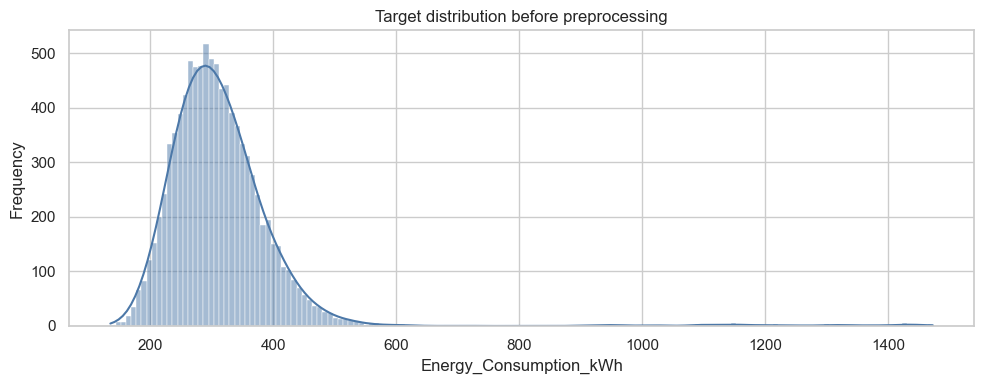

In [43]:
print("Analysis shape:", df.shape)
print("Exact duplicate rows:", int(df.duplicated().sum()))
if "Observation_ID" in df.columns:
    print("Observation_ID unique:", int(df["Observation_ID"].nunique()), "of", len(df))
print("\nData types:")
display(df.dtypes.astype(str).rename("dtype").to_frame())
print("\nNumerical summary:")
display(df.select_dtypes(include=np.number).describe().T)
print("\nCategorical cardinality:")
cat_audit = pd.DataFrame({"unique_nonmissing": df.select_dtypes(include=["object", "category", "bool", "boolean"]).nunique(dropna=True)})
display(cat_audit)
print("\nTarget missing:", int(df[TARGET].isna().sum()))
print("Target distribution:")
display(df[TARGET].value_counts(dropna=False).rename("count").to_frame())
fig, ax = plt.subplots(figsize=(10, 4))
if TASK == "classification":
    order = df[TARGET].value_counts().index
    sns.countplot(data=df, x=TARGET, order=order, color="#4c78a8", ax=ax)
    ax.tick_params(axis="x", rotation=25)
    ax.set_ylabel("Cases")
else:
    sns.histplot(df[TARGET].dropna(), kde=True, color="#4c78a8", ax=ax)
    ax.set_ylabel("Frequency")
ax.set_title("Target distribution before preprocessing")
plt.tight_layout(); save_plot("01_target_distribution_before_preprocessing.png"); plt.show()

## 5. Identify and visualize missing values

Pandas is used for exact counts and percentages. The requested `missingno` matrix is included below. If `missingno` is installed from `requirements.txt`, it renders the library's matrix plot; this execution environment may use the equivalent heatmap fallback if that optional dependency is unavailable.

Missingness mechanisms are not conclusively identifiable from a missingness plot alone. The notebook distinguishes deterministic structural blanks from ordinary missing values and labels uncertain mechanisms cautiously.

,missing_count,missing_pct,dtype
Tool_Wear_Index,600,6.000,float64
Vibration_mm_s,500,5.000,float64
Average_Machine_Temperature_C,400,4.000,float64
Energy_Consumption_kWh,400,4.000,float64
Humidity_pct,300,3.000,float64
Shift,5,0.050,object


Plot saved: /Users/subhankarbiswas/MSCM-CO-07_Data-Analytics-in-Supply-Chain-Management_Team_Project/Part2_preprocessing_only/part2_plots/Notebook-1/02_missingness_matrix_missingno.png


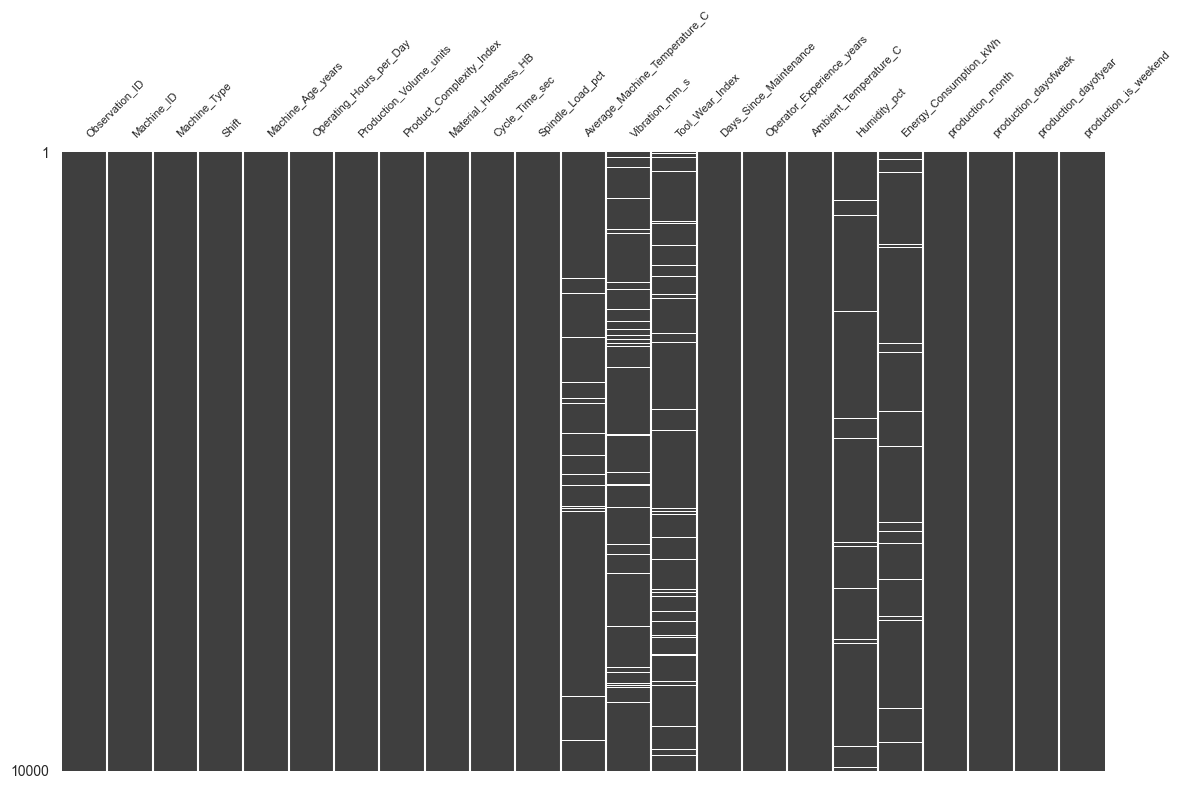

Plot saved: /Users/subhankarbiswas/MSCM-CO-07_Data-Analytics-in-Supply-Chain-Management_Team_Project/Part2_preprocessing_only/part2_plots/Notebook-1/03_missing_value_percentage_by_column.png


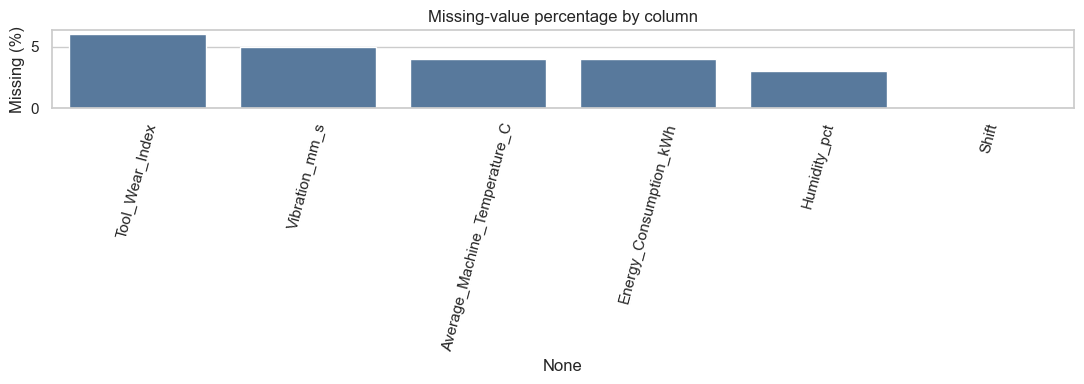

In [44]:
missing_summary = pd.DataFrame({
    "missing_count": df.isna().sum(),
    "missing_pct": (df.isna().mean() * 100).round(2),
    "dtype": df.dtypes.astype(str),
})
missing_summary = missing_summary.loc[missing_summary["missing_count"].gt(0)].sort_values("missing_pct", ascending=False)
display(missing_summary)

fig, ax = plt.subplots(figsize=(11, max(3, 0.35 * max(1, len(df.columns)))))
if HAS_MISSINGNO:
    plt.close(fig)
    msno.matrix(df, figsize=(12, max(4, 0.35 * len(df.columns))), sparkline=False, fontsize=8)
    save_plot("02_missingness_matrix_missingno.png"); plt.show()
else:
    # Visual fallback only; missingno.matrix is used whenever the package is installed.
    sample = df if len(df) <= 1500 else df.sample(1500, random_state=RANDOM_STATE)
    sns.heatmap(sample.isna().T, cbar=False, yticklabels=True, ax=ax, cmap="viridis")
    ax.set_title("Missingness matrix (fallback for missingno.matrix)")
    ax.set_xlabel("Sampled observations")
    plt.tight_layout(); save_plot("02_missingness_matrix_fallback.png"); plt.show()

fig, ax = plt.subplots(figsize=(11, 4))
if len(missing_summary):
    sns.barplot(x=missing_summary.index, y=missing_summary["missing_pct"], color="#4c78a8", ax=ax)
    ax.tick_params(axis="x", rotation=75)
else:
    ax.text(.5, .5, "No missing values found", ha="center", va="center")
ax.set_title("Missing-value percentage by column")
ax.set_ylabel("Missing (%)")
plt.tight_layout(); save_plot("03_missing_value_percentage_by_column.png"); plt.show()

### Missingness mechanism assessment and treatment decision

**Dataset-specific interpretation:** Median imputation is used for numerical predictors because several sensor/condition variables are continuous and may be skewed. Most-frequent imputation is used for nominal predictors. The five `Shift == "Dream"` tokens are treated as unresolved invalid labels and converted to missing before imputation; they are not assigned an invented shift.

The missingness types are interpreted as follows:

- **MCAR (Missing Completely At Random):** missingness is unrelated to observed or unobserved values. This cannot be established from the plot alone.
- **MAR (Missing At Random):** missingness may be explained by observed fields (for example, the route-availability flag).
- **MNAR (Missing Not At Random):** missingness depends on the missing value itself or an unobserved process; this also cannot be confirmed from the available file alone.

Where no deterministic rule or strong observed explanation is available, the mechanism is marked **undetermined (MCAR/MAR cannot be distinguished from this dataset alone)**. Missing values are not filled with arbitrary constants merely to eliminate null counts.

### Dataset-specific missingness mechanism

**Mechanism classification for this file:** Missing sensor predictors (`Average_Machine_Temperature_C`, `Vibration_mm_s`, `Tool_Wear_Index`, `Humidity_pct`) and the 400 missing energy targets have no source metadata explaining why they are absent. Their mechanism is therefore **undetermined**; MCAR cannot be assumed, MAR is plausible if sensor availability depends on machine/maintenance conditions, and the CSV does not support a claim of MNAR. The five `Dream` shift strings are invalid labels recoded to missing (a data-quality correction, not an original null mechanism). Missing target rows are excluded from supervised training because no valid response exists.

## 6. Define predictive inputs and split the data

The target is kept separately from the features. Identifier fields and the leakage-sensitive fields listed below are excluded. The target is never included in `X`. All modelling transformations are fitted after the split.

Rows before target filter: 10000
Rows dropped due to missing target: 400
Usable supervised rows: 9600
Excluded columns: ['Observation_ID']
Feature columns: 21
Train rows: 7,680 (80.0%)
Test rows:  1,920 (20.0%)
Target missing in train/test: 0 0
Plot saved: /Users/subhankarbiswas/MSCM-CO-07_Data-Analytics-in-Supply-Chain-Management_Team_Project/Part2_preprocessing_only/part2_plots/Notebook-1/04_train_test_target_distribution.png


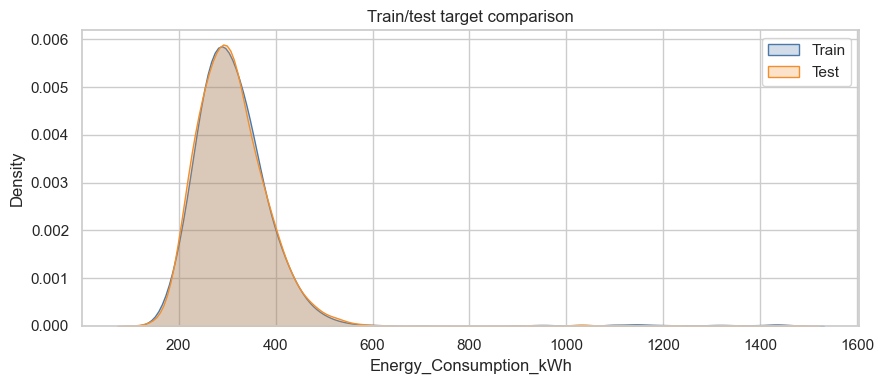

In [45]:
# Drop rows whose supervised target is unavailable; predictors are not used to invent a target.
rows_before_target_filter = len(df)
model_df = df.loc[df[TARGET].notna()].copy()
rows_dropped_missing_target = rows_before_target_filter - len(model_df)

# These exclusions are deliberate feature-selection / leakage decisions.
feature_exclusions = [c for c in EXCLUDE_FEATURES if c in model_df.columns]
X = model_df.drop(columns=[TARGET] + feature_exclusions)
y = model_df[TARGET].copy()

# Retain only columns with at least one observed value in the model sample.
all_missing_features = X.columns[X.isna().all()].tolist()
if all_missing_features:
    X = X.drop(columns=all_missing_features)

print("Rows before target filter:", rows_before_target_filter)
print("Rows dropped due to missing target:", rows_dropped_missing_target)
print("Usable supervised rows:", len(X))
print("Excluded columns:", feature_exclusions + all_missing_features)
print("Feature columns:", len(X.columns))

if TASK == "classification":
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
    )
else:
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.20, random_state=RANDOM_STATE
    )
print(f"Train rows: {len(X_train):,} ({len(X_train)/len(X):.1%})")
print(f"Test rows:  {len(X_test):,} ({len(X_test)/len(X):.1%})")
print("Target missing in train/test:", int(y_train.isna().sum()), int(y_test.isna().sum()))

fig, ax = plt.subplots(figsize=(9, 4))
if TASK == "classification":
    prop = pd.DataFrame({"train": y_train.value_counts(normalize=True), "test": y_test.value_counts(normalize=True)}).fillna(0)
    prop.plot(kind="bar", ax=ax)
    ax.set_ylabel("Class proportion")
    ax.tick_params(axis="x", rotation=25)
else:
    sns.kdeplot(y_train, label="Train", fill=True, alpha=.25, color="#4c78a8", ax=ax)
    sns.kdeplot(y_test, label="Test", fill=True, alpha=.25, color="#f28e2b", ax=ax)
    ax.legend()
    ax.set_ylabel("Density")
ax.set_title("Train/test target comparison")
plt.tight_layout(); save_plot("04_train_test_target_distribution.png"); plt.show()

## 7. Handle missing predictor values

**Chosen approach:** simple imputation, fitted separately on training data. Numerical columns use median values; categorical columns use the most frequent training value. This is transparent, reproducible and avoids using test-set statistics. The before/after comparison below shows how many missing predictor entries are removed by the imputation step.

For the port dataset, the validated structural route-distance blanks are converted to 0 km before splitting while `Alternative_Route_Available` remains an input; this represents the domain rule rather than statistical imputation.

Numerical columns: ['Machine_Age_years', 'Operating_Hours_per_Day', 'Production_Volume_units', 'Product_Complexity_Index', 'Material_Hardness_HB', 'Cycle_Time_sec', 'Spindle_Load_pct', 'Average_Machine_Temperature_C', 'Vibration_mm_s', 'Tool_Wear_Index', 'Days_Since_Maintenance', 'Operator_Experience_years', 'Ambient_Temperature_C', 'Humidity_pct', 'production_month', 'production_dayofweek', 'production_dayofyear']
Categorical / Boolean columns: ['Machine_ID', 'Machine_Type', 'Shift', 'production_is_weekend']
Training predictor missing cells before imputation: 1376
Training predictor missing cells after imputation: 0


,before,after
Tool_Wear_Index,452,0
Vibration_mm_s,380,0
Average_Machine_Temperature_C,315,0
Humidity_pct,224,0
Shift,5,0


Plot saved: /Users/subhankarbiswas/MSCM-CO-07_Data-Analytics-in-Supply-Chain-Management_Team_Project/Part2_preprocessing_only/part2_plots/Notebook-1/05_missing_values_before_after_imputation.png


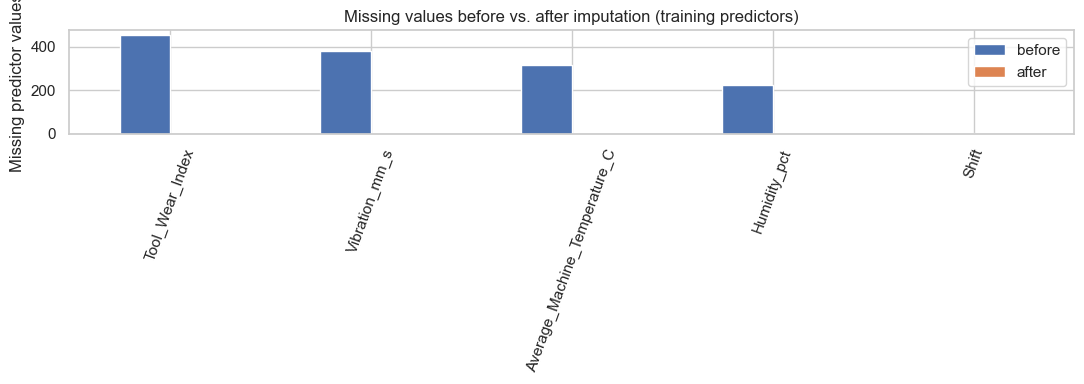

In [46]:
# Identify numeric and categorical predictors from the training partition.
numeric_features = X_train.select_dtypes(include=[np.number]).columns.tolist()
categorical_features = [c for c in X_train.columns if c not in numeric_features]
print("Numerical columns:", numeric_features)
print("Categorical / Boolean columns:", categorical_features)

# Fit imputation only on training data.
num_imputer = SimpleImputer(strategy="median")
cat_imputer = SimpleImputer(strategy="most_frequent")

X_train_num_imp = pd.DataFrame(num_imputer.fit_transform(X_train[numeric_features]),
                               columns=numeric_features, index=X_train.index)
X_test_num_imp = pd.DataFrame(num_imputer.transform(X_test[numeric_features]),
                              columns=numeric_features, index=X_test.index)

if categorical_features:
    X_train_cat_raw = X_train[categorical_features].astype("object").where(X_train[categorical_features].notna(), np.nan)
    X_test_cat_raw = X_test[categorical_features].astype("object").where(X_test[categorical_features].notna(), np.nan)
    X_train_cat_imp = pd.DataFrame(cat_imputer.fit_transform(X_train_cat_raw),
                                   columns=categorical_features, index=X_train.index)
    X_test_cat_imp = pd.DataFrame(cat_imputer.transform(X_test_cat_raw),
                                  columns=categorical_features, index=X_test.index)
else:
    X_train_cat_imp = pd.DataFrame(index=X_train.index)
    X_test_cat_imp = pd.DataFrame(index=X_test.index)

missing_before = int(X_train.isna().sum().sum())
missing_after_imputation = int(X_train_num_imp.isna().sum().sum() + X_train_cat_imp.isna().sum().sum())
print("Training predictor missing cells before imputation:", missing_before)
print("Training predictor missing cells after imputation:", missing_after_imputation)

missing_compare = pd.DataFrame({
    "before": X_train.isna().sum(),
    "after": pd.concat([X_train_num_imp, X_train_cat_imp], axis=1).isna().sum()
}).sort_values("before", ascending=False)
missing_compare = missing_compare[missing_compare["before"].gt(0)]
display(missing_compare)
fig, ax = plt.subplots(figsize=(11, 4))
if len(missing_compare):
    missing_compare.plot(kind="bar", ax=ax)
    ax.set_ylabel("Missing predictor values")
    ax.tick_params(axis="x", rotation=70)
else:
    ax.text(.5,.5,"No missing predictor values in the training partition",ha="center",va="center")
ax.set_title("Missing values before vs. after imputation (training predictors)")
plt.tight_layout(); save_plot("05_missing_values_before_after_imputation.png"); plt.show()

## 8. Detect and handle outliers

**Detection:** IQR rule, with lower/upper fences at Q1 − 1.5 × IQR and Q3 + 1.5 × IQR.  
**Handling:** winsorization (capping) of eligible continuous predictors at the corresponding training-set fences. The fences are learned on training data and reused unchanged on test data.

IQR (1.5 × IQR) is fitted on the training partition only. Winsorization is applied only to continuous predictor columns. Bounded indices/percentages and the ordinal complexity index are not capped automatically. The regression target is diagnosed separately and never winsorized, because high energy use is the outcome being studied.

The target is assessed separately and is never clipped. This is important for regression, where high target values can be legitimate cases rather than data errors.

In [47]:
# IQR screening and train-fitted winsorization bounds.
# Low-cardinality ordinal/bounded fields are excluded from automatic capping by domain review.
outlier_rows = []
iqr_bounds = {}
for col in numeric_features:
    s = X_train_num_imp[col].dropna()
    if s.nunique() < 10 or col in OUTLIER_SKIP:
        continue
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    if not np.isfinite(iqr) or iqr <= 0:
        continue
    lower, upper = q1 - 1.5*iqr, q3 + 1.5*iqr
    n_low = int((s < lower).sum())
    n_high = int((s > upper).sum())
    iqr_bounds[col] = (float(lower), float(upper))
    outlier_rows.append({"feature":col,"Q1":q1,"Q3":q3,"IQR":iqr,
                         "lower_fence":lower,"upper_fence":upper,
                         "low_outliers_train":n_low,"high_outliers_train":n_high,
                         "total_outliers_train":n_low+n_high})
outlier_summary = pd.DataFrame(outlier_rows)
if len(outlier_summary):
    outlier_summary = outlier_summary.sort_values("total_outliers_train", ascending=False)
display(outlier_summary)

# Apply the training-set fences to both partitions. Target values are never modified.
X_train_num_wins = X_train_num_imp.copy()
X_test_num_wins = X_test_num_imp.copy()
for col, (lower, upper) in iqr_bounds.items():
    X_train_num_wins[col] = X_train_num_wins[col].clip(lower, upper)
    X_test_num_wins[col] = X_test_num_wins[col].clip(lower, upper)

print("Eligible continuous features winsorized:", len(iqr_bounds))
print("Training predictor values changed by winsorization:", int((X_train_num_wins != X_train_num_imp).sum().sum()))

# Target outlier audit, when the target is numeric; do not apply handling to y.
if pd.api.types.is_numeric_dtype(y):
    ty = y_train.dropna()
    q1, q3 = ty.quantile([.25,.75]); tiqr = q3-q1
    target_outliers = int(((ty < q1-1.5*tiqr) | (ty > q3+1.5*tiqr)).sum()) if tiqr > 0 else 0
    print("Target IQR outliers in training target (reported, not modified):", target_outliers)

,feature,Q1,Q3,IQR,lower_fence,upper_fence,low_outliers_train,high_outliers_train,total_outliers_train
9,Operator_Experience_years,3.120,8.320,5.200,-4.680,16.120,0,255,255
8,Days_Since_Maintenance,18.100,44.500,26.400,-21.500,84.100,0,228,228
2,Production_Volume_units,405.000,627.000,222.000,72.000,960.000,0,194,194
5,Average_Machine_Temperature_C,70.608,77.480,6.873,60.299,87.789,35,115,150
7,Tool_Wear_Index,0.321,0.524,0.203,0.017,0.829,0,137,137
4,Cycle_Time_sec,75.330,100.882,25.552,37.001,139.211,9,88,97
6,Vibration_mm_s,2.018,2.787,0.769,0.864,3.941,7,84,91
3,Material_Hardness_HB,230.000,276.000,46.000,161.000,345.000,18,21,39
1,Operating_Hours_per_Day,13.520,18.420,4.900,6.170,25.770,29,0,29
0,Machine_Age_years,4.838,12.310,7.473,-6.371,23.519,0,0,0


Eligible continuous features winsorized: 13
Training predictor values changed by winsorization: 1220
Target IQR outliers in training target (reported, not modified): 183


Plot saved: /Users/subhankarbiswas/MSCM-CO-07_Data-Analytics-in-Supply-Chain-Management_Team_Project/Part2_preprocessing_only/part2_plots/Notebook-1/06_outlier_boxplots_before_after_winsorization.png


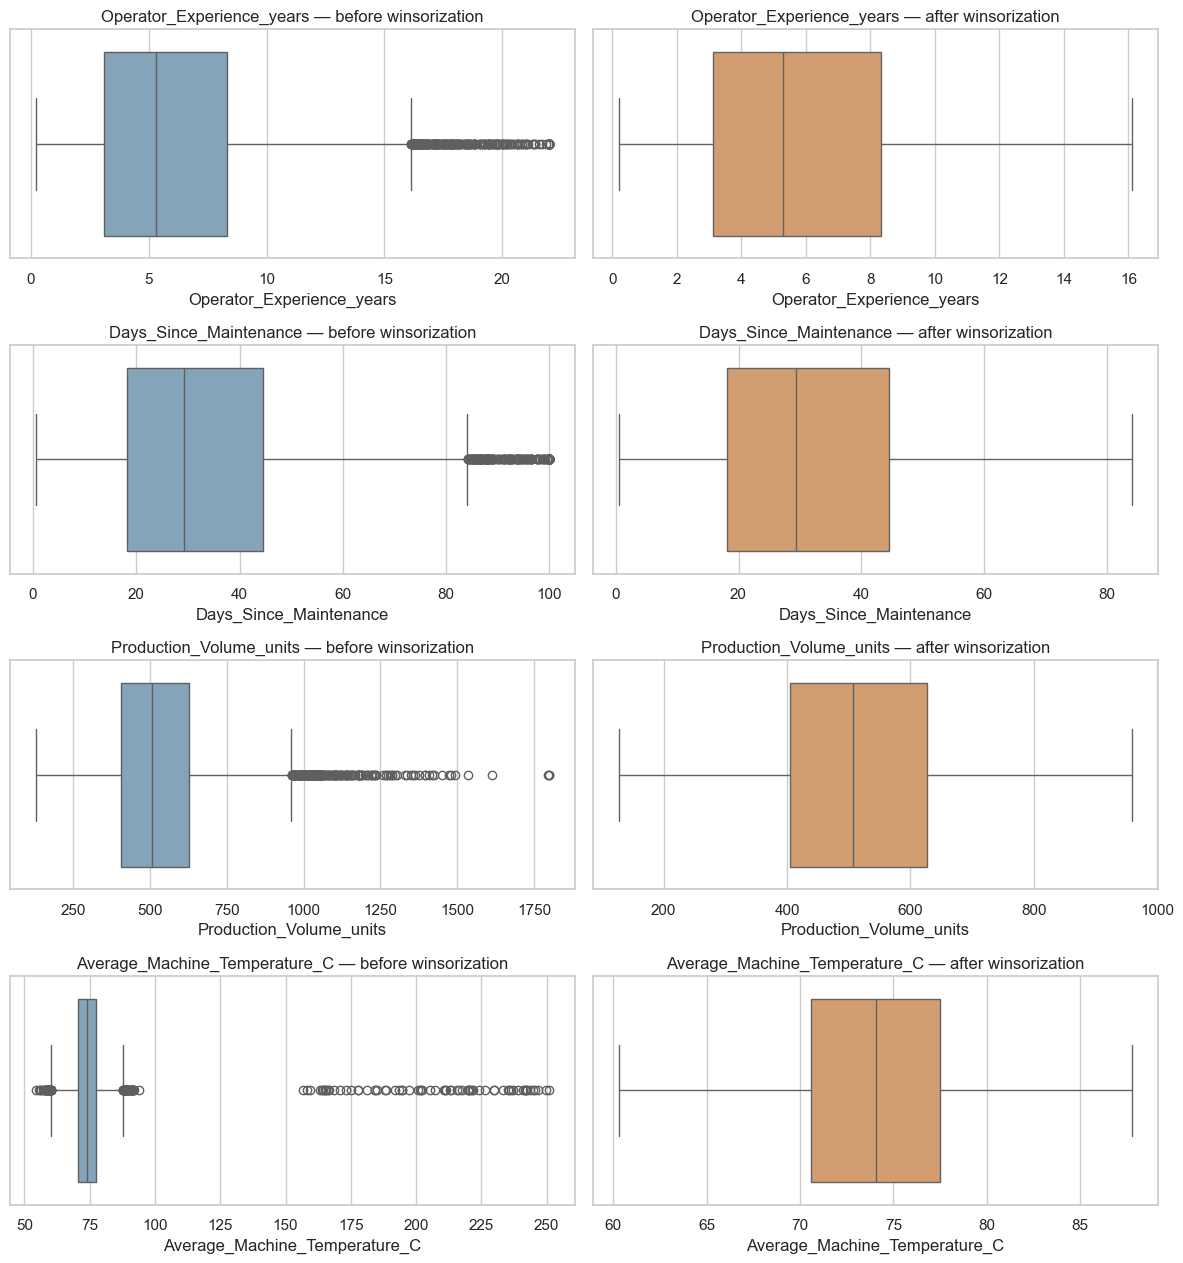

In [48]:
# Visual comparison for the continuous features with the largest training outlier counts.
plot_features = outlier_summary.head(4)["feature"].tolist() if len(outlier_summary) else []
if plot_features:
    fig, axes = plt.subplots(len(plot_features), 2, figsize=(12, 3.2*len(plot_features)))
    if len(plot_features) == 1: axes = np.array([axes])
    for i, col in enumerate(plot_features):
        sns.boxplot(x=X_train_num_imp[col], ax=axes[i,0], color="#7aa6c2")
        axes[i,0].set_title(f"{col} — before winsorization")
        sns.boxplot(x=X_train_num_wins[col], ax=axes[i,1], color="#e39b62")
        axes[i,1].set_title(f"{col} — after winsorization")
    plt.tight_layout(); save_plot("06_outlier_boxplots_before_after_winsorization.png"); plt.show()
else:
    print("No eligible continuous predictor outliers were detected; no winsorization was applied.")

## 9. Encode categorical variables

The categorical columns are listed explicitly. They are nominal in this dataset, so **one-hot encoding** is selected rather than arbitrary integer labels that could imply a false order. Boolean flags are treated as categories. Existing numeric ordinal scales remain numeric and preserve their ordering.

A loop audits each categorical column and its observed levels. The fitted encoder learns its vocabulary from training data only; unseen test categories are safely ignored rather than causing a transform failure.

In [49]:
encoding_audit = []
for col in categorical_features:
    levels = pd.Series(X_train_cat_imp[col]).astype(str).value_counts().index.tolist()
    encoding_audit.append({"column":col,"encoding":"OneHotEncoder","levels_in_train":len(levels),
                           "example_levels":", ".join(levels[:10]),
                           "reason":"Nominal categories; one-hot avoids imposing a false numeric order."})
encoding_plan = pd.DataFrame(encoding_audit)
display(encoding_plan)

# One-hot encode all nominal categorical features using training categories only.
if categorical_features:
    try:
        encoder = OneHotEncoder(handle_unknown="ignore", sparse_output=False)
    except TypeError:  # compatibility with older scikit-learn releases
        encoder = OneHotEncoder(handle_unknown="ignore", sparse=False)
    train_cat_encoded = encoder.fit_transform(X_train_cat_imp.astype(str))
    test_cat_encoded = encoder.transform(X_test_cat_imp.astype(str))
    encoded_names = encoder.get_feature_names_out(categorical_features)
    X_train_cat_encoded = pd.DataFrame(train_cat_encoded, columns=encoded_names, index=X_train.index)
    X_test_cat_encoded = pd.DataFrame(test_cat_encoded, columns=encoded_names, index=X_test.index)
else:
    encoder = None
    X_train_cat_encoded = pd.DataFrame(index=X_train.index)
    X_test_cat_encoded = pd.DataFrame(index=X_test.index)
print("Encoded categorical columns:", len(categorical_features))
print("Generated one-hot features:", X_train_cat_encoded.shape[1])
display(X_train_cat_encoded.head())

,column,encoding,levels_in_train,example_levels,reason
0,Machine_ID,OneHotEncoder,50,"M008, M026, M014, M047, M043, M009, M040, M038...",Nominal categories; one-hot avoids imposing a ...
1,Machine_Type,OneHotEncoder,4,"CNC_Mill, CNC_Grinder, CNC_Lathe, Laser_Cutter",Nominal categories; one-hot avoids imposing a ...
2,Shift,OneHotEncoder,3,"Day, Evening, Night",Nominal categories; one-hot avoids imposing a ...
3,production_is_weekend,OneHotEncoder,2,"False, True",Nominal categories; one-hot avoids imposing a ...


Encoded categorical columns: 4
Generated one-hot features: 59


,Machine_ID_M001,Machine_ID_M002,Machine_ID_M003,Machine_ID_M004,Machine_ID_M005,Machine_ID_M006,Machine_ID_M007,Machine_ID_M008,Machine_ID_M009,Machine_ID_M010,Machine_ID_M011,Machine_ID_M012,Machine_ID_M013,Machine_ID_M014,Machine_ID_M015,Machine_ID_M016,Machine_ID_M017,Machine_ID_M018,Machine_ID_M019,Machine_ID_M020,Machine_ID_M021,Machine_ID_M022,Machine_ID_M023,Machine_ID_M024,Machine_ID_M025,Machine_ID_M026,Machine_ID_M027,Machine_ID_M028,Machine_ID_M029,Machine_ID_M030,Machine_ID_M031,Machine_ID_M032,Machine_ID_M033,Machine_ID_M034,Machine_ID_M035,Machine_ID_M036,Machine_ID_M037,Machine_ID_M038,Machine_ID_M039,Machine_ID_M040,Machine_ID_M041,Machine_ID_M042,Machine_ID_M043,Machine_ID_M044,Machine_ID_M045,Machine_ID_M046,Machine_ID_M047,Machine_ID_M048,Machine_ID_M049,Machine_ID_M050,Machine_Type_CNC_Grinder,Machine_Type_CNC_Lathe,Machine_Type_CNC_Mill,Machine_Type_Laser_Cutter,Shift_Day,Shift_Evening,Shift_Night,production_is_weekend_False,production_is_weekend_True
5355,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,1.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,1.000,0.000,1.000,0.000,0.000,1.000,0.000
8025,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,1.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,1.000,1.000,0.000,0.000,1.000,0.000
3453,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,1.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,1.000,0.000,0.000,1.000,0.000,0.000,1.000,0.000
7356,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,1.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,1.000,0.000,0.000,1.000,0.000,1.000,0.000
1277,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,1.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,1.000,1.000,0.000,0.000,0.000,1.000


## 10. Scale numerical features

**Chosen scaling method: `RobustScaler`.**

The predictors include skewed production, wear, maintenance and sensor measurements, and a number of legitimate extreme observations. RobustScaler uses the training median and interquartile range, reducing sensitivity to long tails while keeping all values in the feature matrix.

The scaler is fitted on the imputed and winsorized training predictors only. The same fitted transform is applied to the test predictors. One-hot encoded indicator columns are not scaled.

In [50]:
scaler = RobustScaler()
if numeric_features:
    train_num_scaled = pd.DataFrame(scaler.fit_transform(X_train_num_wins),
                                    columns=numeric_features, index=X_train.index)
    test_num_scaled = pd.DataFrame(scaler.transform(X_test_num_wins),
                                   columns=numeric_features, index=X_test.index)
else:
    train_num_scaled = pd.DataFrame(index=X_train.index)
    test_num_scaled = pd.DataFrame(index=X_test.index)

X_train_processed = pd.concat([train_num_scaled, X_train_cat_encoded], axis=1)
X_test_processed = pd.concat([test_num_scaled, X_test_cat_encoded], axis=1)
print("Processed train feature matrix:", X_train_processed.shape)
print("Processed test feature matrix:", X_test_processed.shape)
print("Missing values after full preprocessing (train/test):",
      int(X_train_processed.isna().sum().sum()), int(X_test_processed.isna().sum().sum()))

Processed train feature matrix: (7680, 76)
Processed test feature matrix: (1920, 76)
Missing values after full preprocessing (train/test): 0 0


Plot saved: /Users/subhankarbiswas/MSCM-CO-07_Data-Analytics-in-Supply-Chain-Management_Team_Project/Part2_preprocessing_only/part2_plots/Notebook-1/07_numerical_distributions_before_after_robust_scaling.png


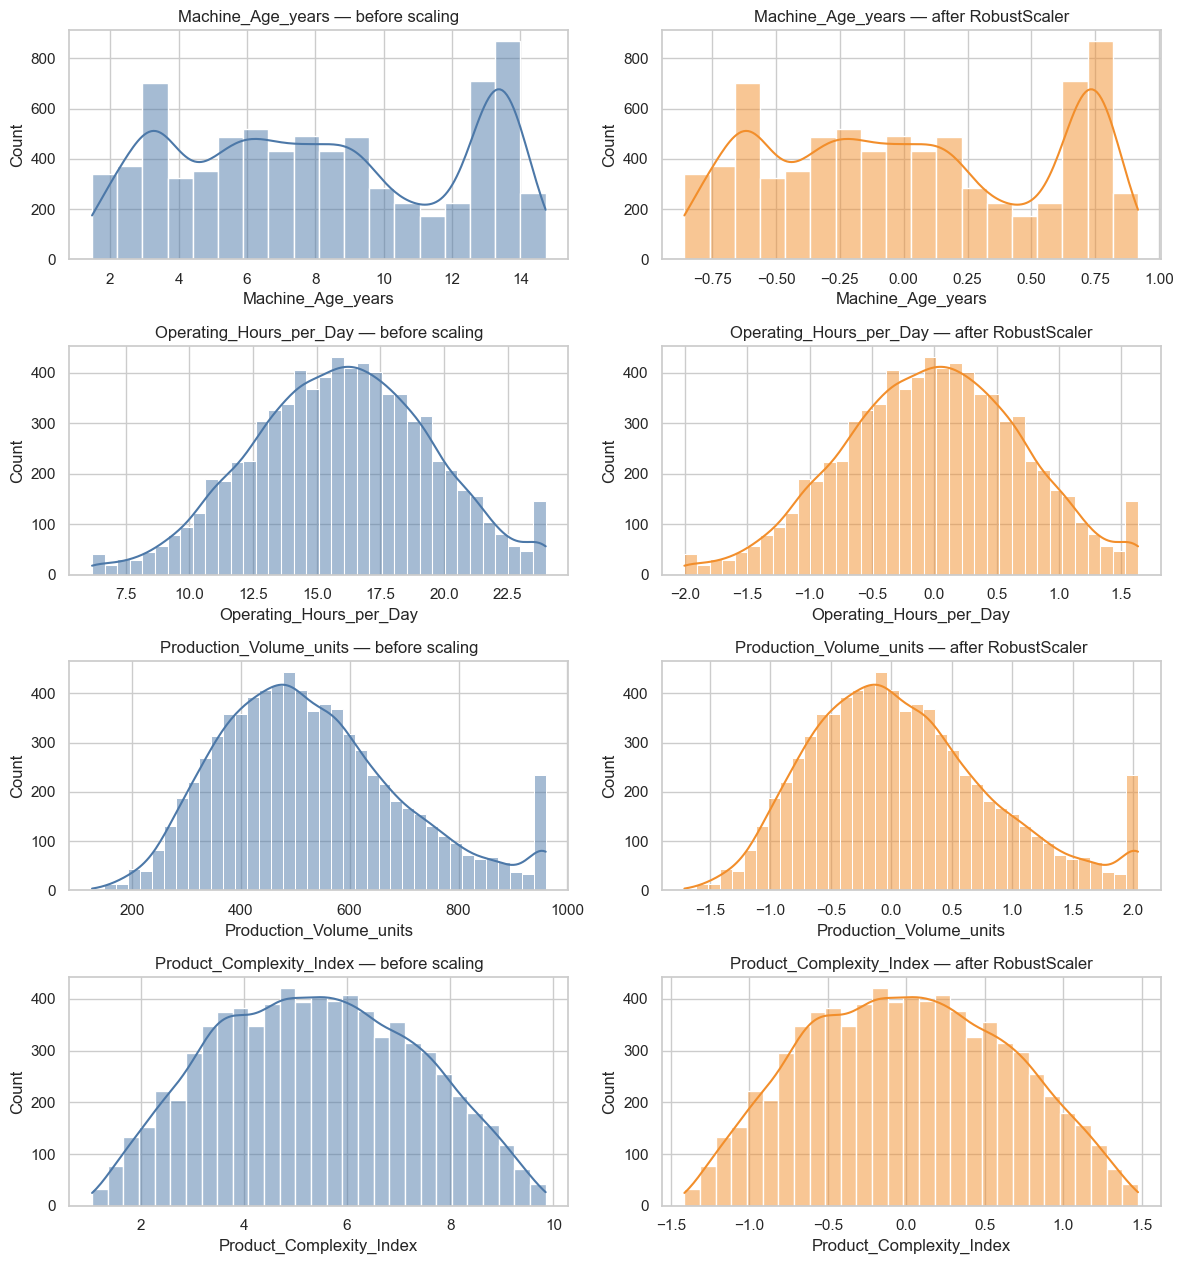

,before_median,before_IQR,after_median,after_IQR
Machine_Age_years,7.885,7.473,0.000,1.000
Operating_Hours_per_Day,15.990,4.900,0.000,1.000
Production_Volume_units,507.000,222.000,0.000,1.000
Product_Complexity_Index,5.360,3.040,0.000,1.000
Material_Hardness_HB,253.000,46.000,0.000,1.000
Cycle_Time_sec,87.785,25.552,0.000,1.000
Spindle_Load_pct,65.640,16.505,0.000,1.000
Average_Machine_Temperature_C,74.060,6.873,0.000,1.000
Vibration_mm_s,2.407,0.769,0.000,1.000
Tool_Wear_Index,0.416,0.203,0.000,1.000


In [51]:
# Compare distributions before and after scaling for up to four numerical variables.
scale_plot_cols = numeric_features[:4]
if scale_plot_cols:
    fig, axes = plt.subplots(len(scale_plot_cols), 2, figsize=(12, 3.2*len(scale_plot_cols)))
    if len(scale_plot_cols) == 1: axes = np.array([axes])
    for i, col in enumerate(scale_plot_cols):
        sns.histplot(X_train_num_wins[col], kde=True, ax=axes[i,0], color="#4c78a8")
        axes[i,0].set_title(f"{col} — before scaling")
        sns.histplot(train_num_scaled[col], kde=True, ax=axes[i,1], color="#f28e2b")
        axes[i,1].set_title(f"{col} — after RobustScaler")
    plt.tight_layout(); save_plot("07_numerical_distributions_before_after_robust_scaling.png"); plt.show()
else:
    print("No numerical predictors required scaling.")

scale_summary = pd.DataFrame({
    "before_median": X_train_num_wins.median() if numeric_features else pd.Series(dtype=float),
    "before_IQR": (X_train_num_wins.quantile(.75)-X_train_num_wins.quantile(.25)) if numeric_features else pd.Series(dtype=float),
    "after_median": train_num_scaled.median() if numeric_features else pd.Series(dtype=float),
    "after_IQR": (train_num_scaled.quantile(.75)-train_num_scaled.quantile(.25)) if numeric_features else pd.Series(dtype=float),
})
display(scale_summary.head(20))

## 11. Relationship diagnostics and preprocessing impact

These plots are diagnostic, not causal evidence. Correlations are calculated on the training partition to avoid using the hold-out set during analysis choices. For regression, numeric associations with the target are shown; for classification, the numeric feature distributions are compared across target classes.

Plot saved: /Users/subhankarbiswas/MSCM-CO-07_Data-Analytics-in-Supply-Chain-Management_Team_Project/Part2_preprocessing_only/part2_plots/Notebook-1/08_training_numerical_correlation_heatmap.png


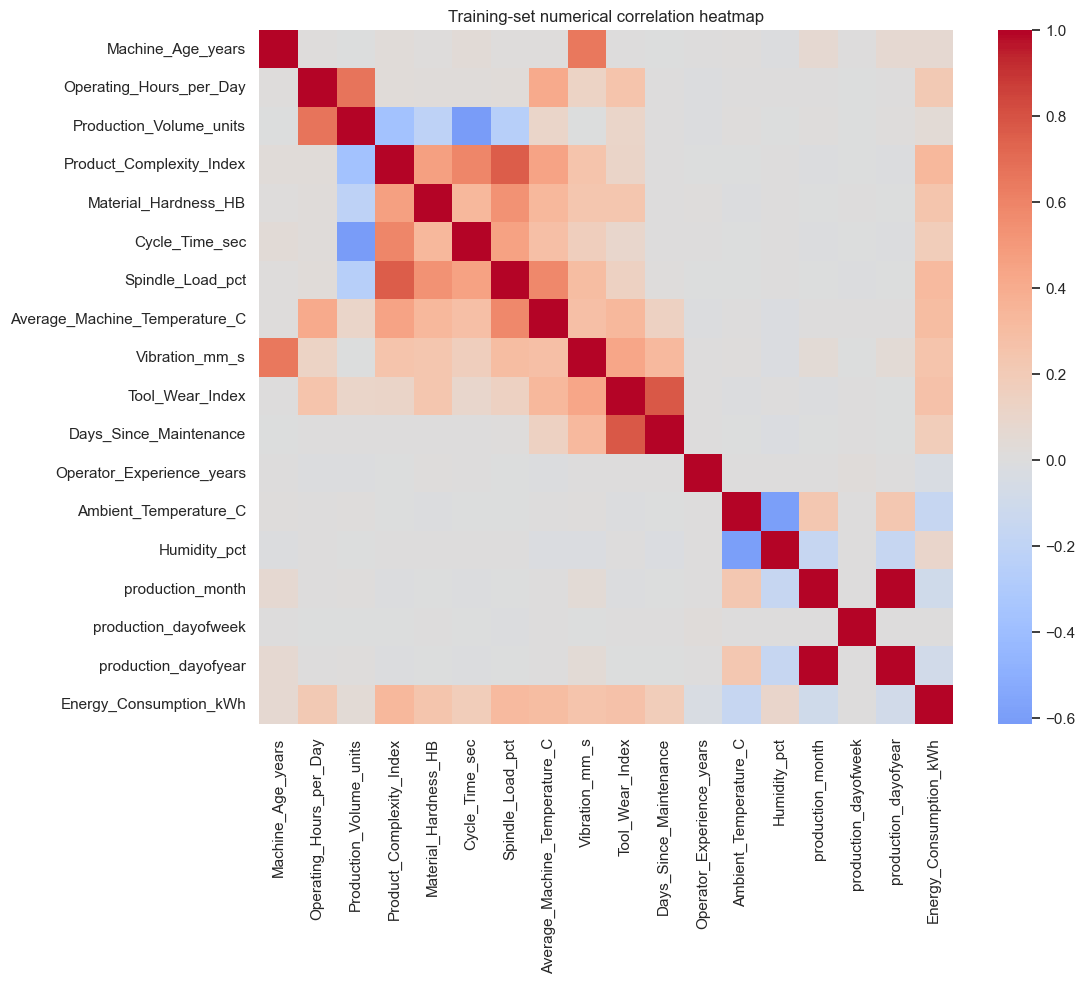

Plot saved: /Users/subhankarbiswas/MSCM-CO-07_Data-Analytics-in-Supply-Chain-Management_Team_Project/Part2_preprocessing_only/part2_plots/Notebook-1/09_top_predictor_relationships_with_target.png


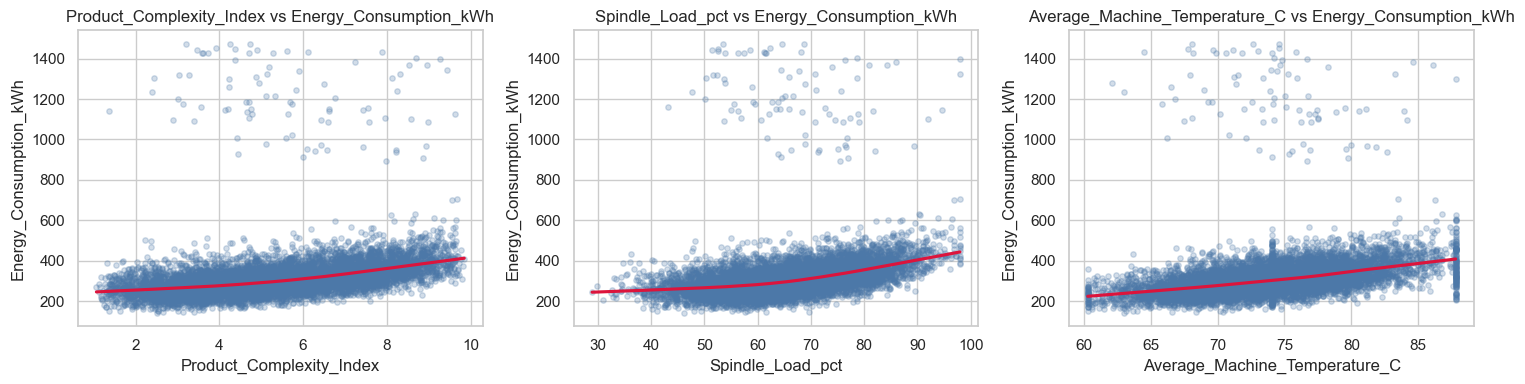

In [52]:
# Correlation heatmap for numeric predictors and numeric regression target.
heat_base = X_train_num_wins.copy()
if pd.api.types.is_numeric_dtype(y_train):
    heat_base[TARGET] = y_train.reindex(heat_base.index)
if heat_base.shape[1] >= 2:
    corr = heat_base.corr(numeric_only=True)
    # Select the most variable columns if the matrix is very wide, for readability.
    if len(corr.columns) > 18:
        chosen = corr.var().sort_values(ascending=False).head(18).index
        corr = corr.loc[chosen, chosen]
    fig, ax = plt.subplots(figsize=(max(8, .65*len(corr)), max(6, .55*len(corr))))
    sns.heatmap(corr, cmap="coolwarm", center=0, annot=len(corr) <= 12, fmt=".2f", square=True, ax=ax)
    ax.set_title("Training-set numerical correlation heatmap")
    plt.tight_layout(); save_plot("08_training_numerical_correlation_heatmap.png"); plt.show()

if TASK == "regression":
    if pd.api.types.is_numeric_dtype(y_train) and len(numeric_features):
        assoc = X_train_num_wins.corrwith(y_train).abs().sort_values(ascending=False)
        assoc = assoc.dropna()
        if len(assoc):
            chosen = assoc.head(3).index.tolist()
            fig, axes = plt.subplots(1, len(chosen), figsize=(5*len(chosen), 4))
            if len(chosen) == 1: axes = [axes]
            for ax, col in zip(axes, chosen):
                sns.regplot(x=X_train_num_wins[col], y=y_train, lowess=True,
                            scatter_kws={"alpha":.25,"s":15}, line_kws={"color":"crimson"}, color="#4c78a8", ax=ax)
                ax.set_title(f"{col} vs {TARGET}")
            plt.tight_layout(); save_plot("09_top_predictor_relationships_with_target.png"); plt.show()
else:
    available = [c for c in numeric_features if c in X_train_num_wins.columns]
    if available:
        # Select up to three predictors with the greatest between-class mean spread.
        grouped = pd.concat([X_train_num_wins[available], y_train.rename(TARGET)], axis=1).groupby(TARGET)[available].mean()
        spread = (grouped.max()-grouped.min()).sort_values(ascending=False)
        chosen = spread.head(3).index.tolist()
        fig, axes = plt.subplots(1, len(chosen), figsize=(5*len(chosen), 4))
        if len(chosen) == 1: axes = [axes]
        plot_df = pd.concat([X_train_num_wins[chosen], y_train.rename(TARGET)], axis=1)
        for ax, col in zip(axes, chosen):
            sns.boxplot(data=plot_df, x=TARGET, y=col, color="#7aa6c2", ax=ax)
            ax.tick_params(axis="x", rotation=25)
            ax.set_title(f"{col} by target class")
        plt.tight_layout(); save_plot("09_numeric_predictor_distributions_by_target_class.png"); plt.show()

## 12. Other preprocessing decisions

Feature engineering derives calendar variables from `Production_Date`. `Machine_Type == "Tree"` is corrected using the stable machine-level type from the same `Machine_ID`; all five affected machine IDs have a non-Tree type elsewhere in the canonical block. `Shift == "Dream"` is unresolved and is therefore treated as missing. No sampling, PCA or discretization is applied; the regression target is continuous and no class-imbalance problem exists.

**Feature selection / leakage control:** `Observation_ID` is a row identifier and is not a predictive input. The target is `Energy_Consumption_kWh`.

**Dimension reduction:** not applied unless the encoded feature-space becomes too large for the next model. Preserving interpretable variables is preferable at this stage.  
**Discretization:** not applied because continuous magnitudes are potentially informative and binning would discard within-bin variation.

In [53]:
# Class imbalance assessment and final model-ready data checks.
if TASK == "classification":
    class_counts = y.value_counts().rename("count").to_frame()
    class_counts["share_pct"] = (class_counts["count"] / len(y) * 100).round(2)
    display(class_counts)
    imbalance_ratio = class_counts["count"].max() / class_counts["count"].min()
    print("Majority/minority class count ratio:", round(float(imbalance_ratio), 3))
    print("Decision: no resampling is performed in this preprocessing notebook; class proportions are not severely skewed for this dataset.")
else:
    print("Class resampling is not applicable to a regression target.")

assert X_train_processed.index.equals(y_train.index)
assert X_test_processed.index.equals(y_test.index)
assert X_train_processed.isna().sum().sum() == 0
assert X_test_processed.isna().sum().sum() == 0
assert TARGET not in X_train_processed.columns
assert TARGET not in X_test_processed.columns
print("\nFinal validation:")
print("Train feature matrix:", X_train_processed.shape, "| test feature matrix:", X_test_processed.shape)
print("Train target:", y_train.shape, "| test target:", y_test.shape)
print("Target leakage check:", TARGET not in X_train_processed.columns and TARGET not in X_test_processed.columns)
print("All processed predictors finite:", bool(np.isfinite(X_train_processed.to_numpy()).all() and np.isfinite(X_test_processed.to_numpy()).all()))

Class resampling is not applicable to a regression target.

Final validation:
Train feature matrix: (7680, 76) | test feature matrix: (1920, 76)
Train target: (7680,) | test target: (1920,)
Target leakage check: True
All processed predictors finite: True


## 13. Export model-ready matrices and final checklist

The processed train and test features and targets are saved separately under `part2_outputs/`. The original source CSV is not modified. These exports allow the next modelling stage to use exactly the same fitted preprocessing decisions. Retain the notebook, source CSV and `requirements.txt` together for reproducibility.

In [54]:
OUTPUT_DIR = Path("part2_outputs") / "Manufacturing_Energy_Consumption"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
X_train_processed.to_csv(OUTPUT_DIR / "X_train_processed.csv", index=True)
X_test_processed.to_csv(OUTPUT_DIR / "X_test_processed.csv", index=True)
pd.DataFrame({TARGET:y_train}).to_csv(OUTPUT_DIR / "y_train.csv", index=True)
pd.DataFrame({TARGET:y_test}).to_csv(OUTPUT_DIR / "y_test.csv", index=True)

final_checks = pd.DataFrame({
    "check":["source CSV unchanged on disk", "usable supervised cases", "train/test split", "processed missing values",
             "target excluded from features", "IQR bounds fit on train only", "encoder fit on train only", "scaler fit on train only"],
    "result":["yes — read-only input", len(X), f"{len(X_train)}/{len(X_test)}", int(X_train_processed.isna().sum().sum()+X_test_processed.isna().sum().sum()),
              TARGET not in X_train_processed.columns, "yes", "yes", "yes"]
})
display(final_checks)
print("Saved outputs to:", OUTPUT_DIR.resolve())

,check,result
0,source CSV unchanged on disk,yes — read-only input
1,usable supervised cases,9600
2,train/test split,7680/1920
3,processed missing values,0
4,target excluded from features,True
5,IQR bounds fit on train only,yes
6,encoder fit on train only,yes
7,scaler fit on train only,yes


Saved outputs to: /Users/subhankarbiswas/MSCM-CO-07_Data-Analytics-in-Supply-Chain-Management_Team_Project/Part2_preprocessing_only/part2_outputs/Manufacturing_Energy_Consumption


## 14. Findings and conclusion

- **Target:** `Energy_Consumption_kWh` (regression).
- **Train/test strategy:** 80/20; split is performed before learned preprocessing steps.
- **Missing data:** Median imputation is used for numerical predictors because several sensor/condition variables are continuous and may be skewed. Most-frequent imputation is used for nominal predictors. The five `Shift == "Dream"` tokens are treated as unresolved invalid labels and converted to missing before imputation; they are not assigned an invented shift.
- **Outliers:** IQR (1.5 × IQR) is fitted on the training partition only. Winsorization is applied only to continuous predictor columns. Bounded indices/percentages and the ordinal complexity index are not capped automatically. The regression target is diagnosed separately and never winsorized, because high energy use is the outcome being studied.
- **Scaling:** RobustScaler; The predictors include skewed production, wear, maintenance and sensor measurements, and a number of legitimate extreme observations. RobustScaler uses the training median and interquartile range, reducing sensitivity to long tails while keeping all values in the feature matrix.
- **Additional processing:** Feature engineering derives calendar variables from `Production_Date`. `Machine_Type == "Tree"` is corrected using the stable machine-level type from the same `Machine_ID`; all five affected machine IDs have a non-Tree type elsewhere in the canonical block. `Shift == "Dream"` is unresolved and is therefore treated as missing. No sampling, PCA or discretization is applied; the regression target is continuous and no class-imbalance problem exists.